# 03 · Dtypes & Numerical Precision

**Module 02 — NumPy & Numerical Computing**

---

## What you will learn

1. The dtype zoo, and how to choose deliberately rather than by accident.
2. **Silent integer overflow** — the promise Module 01 made, paid in full.
3. Type promotion rules, including what changed in NumPy 2.0.
4. `float32` vs `float64`: the memory/speed/accuracy trade-off, quantified.
5. Machine epsilon and catastrophic cancellation.
6. `NaN` and `inf`: how they propagate, and how to control the warnings.
7. Cutting a dataset's memory by 75% with correct downcasting.

**Estimated time:** 75 minutes

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import format_bytes, setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()

rng = np.random.default_rng(seed=42)
print(f"NumPy {np.__version__}")

NumPy 2.5.1


## 1. The dtype zoo

Unlike Python, NumPy uses **fixed-width** types. That is the source of both its
speed and its sharpest edge.

In [2]:
int_types = [np.int8, np.int16, np.int32, np.int64]
uint_types = [np.uint8, np.uint16, np.uint32, np.uint64]

print(f"{'dtype':<10} {'bytes':>6} {'min':>22} {'max':>22}")
print("-" * 62)
for dt in int_types + uint_types:
    info = np.iinfo(dt)
    print(f"{np.dtype(dt).name:<10} {np.dtype(dt).itemsize:>6} "
          f"{info.min:>22,} {info.max:>22,}")

dtype       bytes                    min                    max
--------------------------------------------------------------
int8            1                   -128                    127
int16           2                -32,768                 32,767
int32           4         -2,147,483,648          2,147,483,647
int64           8 -9,223,372,036,854,775,808 9,223,372,036,854,775,807
uint8           1                      0                    255
uint16          2                      0                 65,535
uint32          4                      0          4,294,967,295
uint64          8                      0 18,446,744,073,709,551,615


In [3]:
print(f"{'dtype':<10} {'bytes':>6} {'precision':>10} {'max':>14} {'epsilon':>12}")
print("-" * 56)
for dt in [np.float16, np.float32, np.float64]:
    info = np.finfo(dt)
    print(f"{np.dtype(dt).name:<10} {np.dtype(dt).itemsize:>6} "
          f"{info.precision:>7} dig {info.max:>14.4g} {info.eps:>12.3e}")

dtype       bytes  precision            max      epsilon
--------------------------------------------------------
float16         2       3 dig       6.55e+04    9.766e-04
float32         4       6 dig      3.403e+38    1.192e-07
float64         8      15 dig     1.798e+308    2.220e-16


`precision` is the number of **decimal digits you can trust**. `float32` gives
you about 7; `float64` about 15. That number decides whether a computation is
trustworthy, and it is worth committing to memory.

## 2. Silent integer overflow

Module 01 warned that NumPy integers wrap around instead of growing. Here is the
full picture — and it is worse than "it wraps", because of *where* it stays
silent.

In [4]:
# A Python int grows without limit.
print(f"Python : {2**62 * 2:,}")

# An int64 array does not. 2**63 is one past the ceiling.
arr = np.array([2**62], dtype=np.int64)
print(f"int64  : {(arr * 2)[0]:,}   ← wrapped to the most negative value")
print(f"\nint64 max : {np.iinfo(np.int64).max:,}")

Python : 9,223,372,036,854,775,808
int64  : -9,223,372,036,854,775,808   ← wrapped to the most negative value

int64 max : 9,223,372,036,854,775,807


### The dangerous part: arrays wrap without warning

In [5]:
small = np.array([127], dtype=np.int8)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    result = small + 1

print(f"np.array([127], dtype=int8) + 1  →  {result[0]}")
print(f"warnings emitted : {len(caught)}   ← none at all")

# The scalar path DOES warn, which makes the inconsistency easy to miss.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    scalar_result = np.int8(127) + 1

print(f"\nnp.int8(127) + 1                 →  {scalar_result}")
print(f"warnings emitted : {len(caught)}   "
      f"({caught[0].category.__name__ if caught else 'none'})")

np.array([127], dtype=int8) + 1  →  -128
warnings emitted : 0   ← none at all

np.int8(127) + 1                 →  -128
warnings emitted : 1   (RuntimeWarning)


> [!WARNING]
> **Array arithmetic overflows silently.** No exception, no warning — just a
> wrong number that flows into every downstream aggregate. In a revenue
> pipeline this shows up as a negative total; in an ID column it shows up as
> collisions. Neither is caught by a test that only checks for nulls.

### Where this actually bites — and where it does not

The nuance here is worth getting exactly right, because the intuitive answer is
wrong. Consider daily page views stored as `int32` to save memory:

In [6]:
daily_views = np.full(400, 8_000_000, dtype=np.int32)
true_total = 400 * 8_000_000

print(f"int32 max  : {np.iinfo(np.int32).max:,}")
print(f"true total : {true_total:,}   ← well past the ceiling\n")

print(f"daily_views.sum()             : {daily_views.sum():,}")
print(f"  …its dtype                  : {daily_views.sum().dtype}   ← promoted!")
print(f"daily_views.sum(dtype=int32)  : {daily_views.sum(dtype=np.int32):,}   ← wrapped")
print(f"(daily_views * 400)[0]        : {(daily_views * 400)[0]:,}   ← wrapped")

int32 max  : 2,147,483,647
true total : 3,200,000,000   ← well past the ceiling

daily_views.sum()             : 3,200,000,000
  …its dtype                  : int64   ← promoted!
daily_views.sum(dtype=int32)  : -1,094,967,296   ← wrapped
(daily_views * 400)[0]        : -1,094,967,296   ← wrapped


**Reductions are safer than you would expect; element-wise arithmetic is not.**

`sum`, `mean`, `prod` and `cumsum` promote the *accumulator* to the platform's
default integer (`int64` here) when the input is a narrower integer type. So
`int32_array.sum()` is safe out of the box.

Element-wise operations — `*`, `+`, `**` — get no such protection. The result
keeps the input dtype and wraps in silence. **That is where the bug lives:**
not in the aggregation you were worried about, but in the innocuous
`views * price` two lines earlier.

In [7]:
# The defensive pattern for element-wise work: widen first, deliberately.
views = np.full(5, 2_000_000_000, dtype=np.int32)

print(f"views * 2 (int32)            : {(views * 2)[0]:,}   ← wrapped")
print(f"views.astype(np.int64) * 2   : {(views.astype(np.int64) * 2)[0]:,}   ← correct")

views * 2 (int32)            : -294,967,296   ← wrapped
views.astype(np.int64) * 2   : 4,000,000,000   ← correct


> [!TIP]
> `sum` accepts a `dtype=` argument that forces the accumulator. Use it when
> summing `float32` (see section 4) or when you have overridden the default.

### Detecting overflow rather than hoping

`np.errstate` controls how NumPy reports floating-point and integer errors.
Setting it to `"raise"` converts silence into an exception.

In [8]:
values = np.array([2**30, 2**30], dtype=np.int32)

# Default: silent.
print(f"default        : {(values * 4)[0]}")

# Opt into loudness. Note this covers ufunc errors; use it around the risky part.
try:
    with np.errstate(over="raise"):
        _ = np.multiply(values, 4, dtype=np.int32)
except FloatingPointError as exc:
    print(f"errstate=raise : FloatingPointError — {exc}")

default        : 0


## 3. Type promotion

When operands differ, NumPy promotes to a type that can hold both. NumPy 2.0
changed this materially (NEP 50), so examples written before 2023 may not match
what you see.

In [9]:
cases = [
    ("int32 array + int64 array", np.array([1], np.int32) + np.array([1], np.int64)),
    ("int32 array + float32 array", np.array([1], np.int32) + np.array([1], np.float32)),
    ("float32 array + float64 array", np.array([1], np.float32) + np.array([1], np.float64)),
    ("int array + bool array", np.array([1]) + np.array([True])),
    ("float32 array + Python float", np.array([1], np.float32) + 1.0),
    ("int32 array + Python int", np.array([1], np.int32) + 1),
]

print(f"{'expression':<32} {'result dtype':>14}")
print("-" * 48)
for label, result in cases:
    print(f"{label:<32} {str(result.dtype):>14}")

expression                         result dtype
------------------------------------------------
int32 array + int64 array                 int64
int32 array + float32 array             float64
float32 array + float64 array           float64
int array + bool array                    int64
float32 array + Python float            float32
int32 array + Python int                  int32


The last two lines are the NEP 50 change, and they matter:

**A Python scalar no longer upcasts an array.** `float32_array + 1.0` stays
`float32`. Before NumPy 2.0 it became `float64`, silently doubling memory in
deep-learning pipelines. The new rule is "the array wins", which is both more
predictable and usually what you wanted.

In [10]:
# You can always ask what two types will produce, without running the operation.
print(f"promote_types(int8, int16)     : {np.promote_types(np.int8, np.int16)}")
print(f"promote_types(int32, float32)  : {np.promote_types(np.int32, np.float32)}")
print(f"promote_types(int64, float32)  : {np.promote_types(np.int64, np.float32)}"
      f"   ← float64: neither can hold the other")
print(f"result_type(arr, 2.5)          : "
      f"{np.result_type(np.array([1], np.int32), 2.5)}")

promote_types(int8, int16)     : int16
promote_types(int32, float32)  : float64
promote_types(int64, float32)  : float64   ← float64: neither can hold the other
result_type(arr, 2.5)          : float64


### Integer division always produces a float

In [11]:
a = np.array([7, 8, 9], dtype=np.int32)

print(f"a / 2   : {a / 2}   dtype={(a / 2).dtype}   ← true division")
print(f"a // 2  : {a // 2}         dtype={(a // 2).dtype}   ← floor division keeps int")

# The consequence people trip over: `/` silently doubles your memory.
print(f"\na.nbytes       : {a.nbytes} bytes")
print(f"(a / 2).nbytes : {(a / 2).nbytes} bytes")

a / 2   : [3.5 4.  4.5]   dtype=float64   ← true division
a // 2  : [3 4 4]         dtype=int32   ← floor division keeps int

a.nbytes       : 12 bytes
(a / 2).nbytes : 24 bytes


## 4. `float32` versus `float64`

`float64` is NumPy's default and the right choice most of the time. `float32`
halves memory and often runs faster — at the cost of about 8 decimal digits of
precision. Deep learning uses `float32` (and `float16`) universally; statistics
usually should not.

In [12]:
n = 5_000_000
f64 = rng.random(n)
f32 = f64.astype(np.float32)

print(f"float64 : {format_bytes(f64.nbytes)}")
print(f"float32 : {format_bytes(f32.nbytes)}   ← half")

def best_of(fn, arr, repeats: int = 5) -> float:
    """Return the fastest of `repeats` runs, in seconds."""
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        fn(arr)
        best = min(best, time.perf_counter() - start)
    return best


t64 = best_of(np.sum, f64)
t32 = best_of(np.sum, f32)

print(f"\nsum, float64 : {t64 * 1000:6.2f} ms")
print(f"sum, float32 : {t32 * 1000:6.2f} ms   ({t64 / t32:.2f}× faster)")

float64 : 38.1 MiB
float32 : 19.1 MiB   ← half

sum, float64 :   2.52 ms
sum, float32 :   1.98 ms   (1.27× faster)


### The accuracy cost — absorption

The starkest failure mode is **absorption**: adding a small number to a large
one and having it vanish entirely, because the result cannot represent the
difference.

In [13]:
big32 = np.float32(1e8)
big64 = np.float64(1e8)

print(f"float32 : 1e8 + 1 == 1e8 ?  {big32 + np.float32(1) == big32}   ← the 1 is GONE")
print(f"float64 : 1e8 + 1 == 1e8 ?  {big64 + np.float64(1) == big64}")

# The threshold where it happens is just eps × magnitude.
print(f"\nfloat32 resolution near 1e8 : "
      f"{np.spacing(np.float32(1e8)):.4g}")
print(f"float64 resolution near 1e8 : {np.spacing(np.float64(1e8)):.4g}")

float32 : 1e8 + 1 == 1e8 ?  True   ← the 1 is GONE
float64 : 1e8 + 1 == 1e8 ?  False

float32 resolution near 1e8 : 8
float64 resolution near 1e8 : 1.49e-08


### The accuracy cost — accumulation

In [14]:
values_64 = np.full(10_000_000, 0.1, dtype=np.float64)
values_32 = values_64.astype(np.float32)
true_answer = 10_000_000 * 0.1

sum_64 = values_64.sum()
sum_32 = values_32.sum()

print(f"true answer : {true_answer:,.4f}")
print(f"float64 sum : {sum_64:,.4f}   absolute error {abs(sum_64 - true_answer):.4g}")
print(f"float32 sum : {sum_32:,.4f}   absolute error {abs(sum_32 - true_answer):.4g}")

true answer : 1,000,000.0000
float64 sum : 1,000,000.0000   absolute error 0
float32 sum : 1,000,000.1250   absolute error 0.125


> [!NOTE]
> `float32` is off by only 0.125 in ten million — far better than you might
> fear. The reason is that **NumPy's `.sum()` uses pairwise summation**, which
> keeps error growing like √n instead of n. You are benefiting from a good
> algorithm, not from `float32` being accurate.

Write the naive running total yourself and the protection disappears:

In [15]:
naive = np.float32(0.0)
for _ in range(1_000_000):
    naive = np.float32(naive + np.float32(0.1))

expected = 100_000.0
print(f"naive float32 running total : {naive:,.2f}")
print(f"true answer                 : {expected:,.2f}")
print(f"relative error              : {abs(naive - expected) / expected:.2%}")
print(f"\nnp.sum on the same data     : "
      f"{np.full(1_000_000, 0.1, dtype=np.float32).sum():,.2f}")

naive float32 running total : 100,958.34
true answer                 : 100,000.00
relative error              : 0.96%

np.sum on the same data     : 100,000.01


**Nearly 1% error** from a loop that looks entirely reasonable. This is the
single best argument for never hand-rolling a numerical routine you could call
from the library instead.

When you must sum `float32` data, widen the accumulator:

In [16]:
print(f"values_32.sum()                  : {values_32.sum():,.4f}")
print(f"values_32.sum(dtype=np.float64)  : "
      f"{values_32.sum(dtype=np.float64):,.4f}   ← exact")

values_32.sum()                  : 1,000,000.1250
values_32.sum(dtype=np.float64)  : 1,000,000.0149   ← exact


## 5. Machine epsilon and catastrophic cancellation

**Epsilon** is the smallest number that still changes 1.0 when added to it. It
sets the resolution of the whole type.

In [17]:
for dt in [np.float32, np.float64]:
    eps = np.finfo(dt).eps
    one = dt(1.0)
    print(f"{np.dtype(dt).name}: eps = {eps:.3e}")
    print(f"   1 + eps   != 1 : {one + dt(eps) != one}")
    print(f"   1 + eps/2 != 1 : {one + dt(eps / 2) != one}   ← lost entirely")

float32: eps = 1.192e-07
   1 + eps   != 1 : True
   1 + eps/2 != 1 : False   ← lost entirely
float64: eps = 2.220e-16
   1 + eps   != 1 : True
   1 + eps/2 != 1 : False   ← lost entirely


### Catastrophic cancellation

Subtracting two nearly-equal numbers destroys precision: the leading digits
cancel, and what remains is the rounding error. This is the classic numerical
trap, and it hides inside innocent-looking formulas.

In [18]:
# The textbook variance formula, E[x²] - E[x]², versus the two-pass formula.
data = np.array([1e8 + 1, 1e8 + 2, 1e8 + 3, 1e8 + 4], dtype=np.float64)

naive = (data**2).mean() - data.mean() ** 2      # algebraically correct
stable = ((data - data.mean()) ** 2).mean()      # numerically stable
reference = np.var(data)                          # what NumPy actually does

print(f"data          : {data}")
print(f"\nnaive  E[x²]-E[x]²  : {naive:.10f}   ← nonsense")
print(f"stable E[(x-µ)²]    : {stable:.10f}")
print(f"np.var              : {reference:.10f}")
print(f"\ntrue variance of [1,2,3,4] is 1.25")

data          : [1.00000001e+08 1.00000002e+08 1.00000003e+08 1.00000004e+08]

naive  E[x²]-E[x]²  : 2.0000000000   ← nonsense
stable E[(x-µ)²]    : 1.2500000000
np.var              : 1.2500000000

true variance of [1,2,3,4] is 1.25


The naive formula subtracts two numbers around 10¹⁶ to get an answer around 1.
Sixteen significant digits cancel, and `float64` only has about fifteen — so
the result is entirely rounding noise.

**This is why you use `np.var` rather than writing the formula yourself.** The
library implements the stable version. The lesson generalises: for standard
numerical operations, prefer the library function to the textbook expression.

## 6. `NaN` and `inf`

In [19]:
special = np.array([1.0, np.nan, np.inf, -np.inf, 0.0])

print(f"array     : {special}")
print(f"isnan     : {np.isnan(special)}")
print(f"isinf     : {np.isinf(special)}")
print(f"isfinite  : {np.isfinite(special)}   ← the one you usually want")

array     : [  1.  nan  inf -inf   0.]
isnan     : [False  True False False False]
isinf     : [False False  True  True False]
isfinite  : [ True False False False  True]   ← the one you usually want


### NaN propagates through everything

In [20]:
values = np.array([1.0, 2.0, np.nan, 4.0])

print(f"values.sum()     : {values.sum()}   ← one NaN poisons the result")
print(f"values.mean()    : {values.mean()}")
print(f"\nnp.nansum()      : {np.nansum(values)}   ← NaN-aware variants")
print(f"np.nanmean()     : {np.nanmean(values)}")
print(f"np.nanstd()      : {np.nanstd(values):.4f}")
print(f"np.nanmax()      : {np.nanmax(values)}")

values.sum()     : nan   ← one NaN poisons the result
values.mean()    : nan

np.nansum()      : 7.0   ← NaN-aware variants
np.nanmean()     : 2.3333333333333335
np.nanstd()      : 1.2472
np.nanmax()      : 4.0


> [!WARNING]
> The `nan*` functions **skip** missing values. That is convenient and
> sometimes wrong: `nanmean` of `[1, nan, nan, nan]` is `1.0`, computed from a
> single observation, and it will not tell you. Always check the count too.

In [21]:
partly_missing = np.array([1.0, np.nan, np.nan, np.nan])

print(f"nanmean : {np.nanmean(partly_missing)}")
print(f"based on {np.isfinite(partly_missing).sum()} of "
      f"{partly_missing.size} values  ← report this alongside the mean")

nanmean : 1.0
based on 1 of 4 values  ← report this alongside the mean


### Controlling the warnings

In [22]:
a = np.array([1.0, 0.0, -1.0])

# Division by zero warns by default and produces inf / -inf / nan.
with np.errstate(divide="ignore", invalid="ignore"):
    result = 1.0 / a
print(f"1/[1, 0, -1] with warnings suppressed : {result}")

# Turn them into errors while debugging — much easier than hunting a NaN
# backwards through ten transformations.
try:
    with np.errstate(divide="raise"):
        _ = 1.0 / a
except FloatingPointError as exc:
    print(f"errstate=raise : FloatingPointError — {exc}")

# The safe pattern for element-wise division with a guard.
safe = np.divide(1.0, a, out=np.full_like(a, np.nan), where=(a != 0))
print(f"\nnp.divide with where=  : {safe}   ← no warning, explicit NaN")

1/[1, 0, -1] with warnings suppressed : [ 1. inf -1.]
errstate=raise : FloatingPointError — divide by zero encountered in divide

np.divide with where=  : [ 1. nan -1.]   ← no warning, explicit NaN


## 7. Cutting memory with correct downcasting

Choosing the narrowest *safe* dtype is one of the highest-leverage optimisations
in data work — but "narrowest" must be verified, not guessed.

In [23]:
n_rows = 1_000_000

dataset = {
    "user_id": rng.integers(1, 500_000, n_rows),           # int64 by default
    "age": rng.integers(18, 95, n_rows),
    "n_sessions": rng.integers(0, 300, n_rows),
    "score": rng.random(n_rows) * 100,                      # float64
    "is_active": rng.integers(0, 2, n_rows).astype(bool),
}

before = sum(v.nbytes for v in dataset.values())
print(f"before downcasting : {format_bytes(before)}")
for name, col in dataset.items():
    print(f"  {name:<12} {str(col.dtype):<8} {format_bytes(col.nbytes):>10}")

before downcasting : 31.5 MiB
  user_id      int64       7.6 MiB
  age          int64       7.6 MiB
  n_sessions   int64       7.6 MiB
  score        float64     7.6 MiB
  is_active    bool      976.6 KiB


In [24]:
def safe_downcast(arr: np.ndarray) -> np.ndarray:
    """Return `arr` in the narrowest dtype that represents it exactly.

    Integers are checked against each type's real limits; floats are demoted to
    float32 only when the round trip is lossless for this data.

    Returns
    -------
    ndarray
        A new array, or the original when no narrower type is safe.
    """
    if arr.dtype == bool:
        return arr                      # already 1 byte

    if np.issubdtype(arr.dtype, np.integer):
        low, high = arr.min(), arr.max()
        # Try narrowest first; np.can_cast checks the VALUES, not just the type.
        candidates = ([np.uint8, np.uint16, np.uint32] if low >= 0
                      else [np.int8, np.int16, np.int32])
        for candidate in candidates:
            info = np.iinfo(candidate)
            if low >= info.min and high <= info.max:
                return arr.astype(candidate)
        return arr

    if np.issubdtype(arr.dtype, np.floating):
        demoted = arr.astype(np.float32)
        # Only accept the demotion if nothing changed. For scores in [0, 100]
        # this holds; for values needing 15 digits it will not.
        if np.array_equal(demoted.astype(arr.dtype), arr):
            return demoted
        return arr

    return arr


optimised = {name: safe_downcast(col) for name, col in dataset.items()}
after = sum(v.nbytes for v in optimised.values())

print(f"{'column':<12} {'before':>10} {'after':>10}  {'dtype':>10}")
print("-" * 46)
for name in dataset:
    print(f"{name:<12} {format_bytes(dataset[name].nbytes):>10} "
          f"{format_bytes(optimised[name].nbytes):>10}  "
          f"{str(optimised[name].dtype):>10}")

print(f"\ntotal : {format_bytes(before)} → {format_bytes(after)}  "
      f"({1 - after / before:.0%} saved)")

column           before      after       dtype
----------------------------------------------
user_id         7.6 MiB    3.8 MiB      uint32
age             7.6 MiB  976.6 KiB       uint8
n_sessions      7.6 MiB    1.9 MiB      uint16
score           7.6 MiB    7.6 MiB     float64
is_active     976.6 KiB  976.6 KiB        bool

total : 31.5 MiB → 15.3 MiB  (52% saved)


In [25]:
# Verify nothing was corrupted — a downcast that loses data is not an optimisation.
for name in dataset:
    original, small = dataset[name], optimised[name]
    if np.issubdtype(original.dtype, np.floating):
        identical = np.allclose(original, small, rtol=1e-6)
    else:
        identical = np.array_equal(original, small)
    print(f"  {'✔' if identical else '✘'}  {name} preserved")

  ✔  user_id preserved
  ✔  age preserved
  ✔  n_sessions preserved
  ✔  score preserved
  ✔  is_active preserved


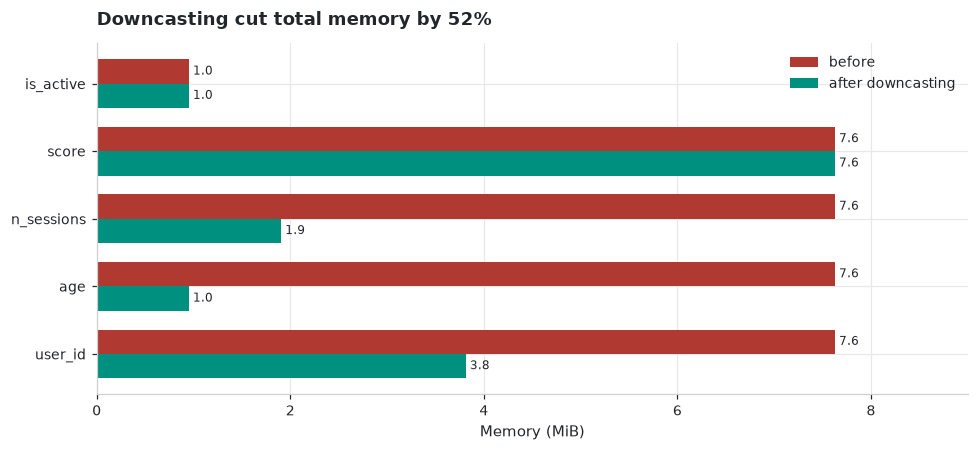

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.2))

names = list(dataset)
before_mb = [dataset[k].nbytes / 1024**2 for k in names]
after_mb = [optimised[k].nbytes / 1024**2 for k in names]

y = np.arange(len(names))
height = 0.36

ax.barh(y + height / 2, before_mb, height, label="before",
        color=COLORS["danger"])
ax.barh(y - height / 2, after_mb, height, label="after downcasting",
        color=COLORS["teal"])

ax.set_yticks(y, names)
ax.set_xlabel("Memory (MiB)")
ax.set_title(f"Downcasting cut total memory by {1 - after / before:.0%}")
ax.legend()

for i, (b, a_) in enumerate(zip(before_mb, after_mb, strict=True)):
    ax.text(b, i + height / 2, f" {b:.1f}", va="center", fontsize=8,
            color=COLORS["text"])
    ax.text(a_, i - height / 2, f" {a_:.1f}", va="center", fontsize=8,
            color=COLORS["text"])

ax.set_xlim(0, max(before_mb) * 1.18)
fig.tight_layout()
plt.show()

> [!WARNING]
> **Downcast IDs with care.** An `int32` holds up to ~2.1 billion — fine for a
> user ID today, and a silent collision the day the table grows. When a column
> is a key rather than a measurement, leave it wide, or store it as a string.

## 8. `datetime64` and `timedelta64`

In [27]:
dates = np.array(["2024-01-15", "2024-06-30", "2024-12-31"], dtype="datetime64[D]")

print(f"dates      : {dates}")
print(f"dtype      : {dates.dtype}   ← [D] is the resolution: day")
print(f"differences: {np.diff(dates)}")
print(f"\nas datetime64[h] : {dates.astype('datetime64[h]')}")

# Arithmetic works naturally.
one_week = np.timedelta64(7, "D")
print(f"\ndates + 1 week : {dates + one_week}")
print(f"days since 2024-01-01 : "
      f"{(dates - np.datetime64('2024-01-01')).astype(int)}")

dates      : ['2024-01-15' '2024-06-30' '2024-12-31']
dtype      : datetime64[D]   ← [D] is the resolution: day
differences: [167 184]

as datetime64[h] : ['2024-01-15T00' '2024-06-30T00' '2024-12-31T00']

dates + 1 week : ['2024-01-22' '2024-07-07' '2025-01-07']
days since 2024-01-01 : [ 14 181 365]


> [!NOTE]
> `datetime64` has no time zone. It represents a naive instant. For anything
> involving zones or calendars, pandas' `Timestamp` (Module 03) is the right
> tool — it wraps `datetime64` and adds the missing semantics.

## 9. Exercises

### Exercise 3.1 — Predict the dtype

Give the result dtype for each, then verify:

```python
np.array([1, 2], dtype=np.int8) + np.array([1, 2], dtype=np.int16)
np.array([1, 2], dtype=np.int32) / 2
np.array([1.0], dtype=np.float32) + 1.0
np.array([1.0], dtype=np.float32) + np.float64(1.0)
np.array([True, False]) + np.array([1, 2])
np.arange(3) ** 2
```

### Exercise 3.2 — Trigger and then prevent an overflow

Build an `int16` array whose sum overflows. Show the wrong answer, then produce
the right one two different ways.

### Exercise 3.3 — When is float32 not enough?

Find the array size at which summing `float32` values of 0.1 drifts more than
0.1% from the true total. Plot relative error against size for both `float32`
and `float64`.

### Exercise 3.4 — Build a memory report

Write `memory_report(arrays: dict) -> None` that prints, per column: current
dtype, current size, the narrowest safe dtype, and the potential saving. Refuse
to suggest a downcast for any column whose name ends in `_id`.

### Exercise 3.5 — Catastrophic cancellation in the wild

The formula for the standard error of a proportion is `sqrt(p*(1-p)/n)`. For
`p = 1 - 1e-17` and `n = 1000`, compute it directly and then via a rearranged
form. Explain the difference.

## Key takeaways

- NumPy dtypes are **fixed-width**. Integers wrap; they do not grow.
- **Array overflow is silent** — no warning at all. Only the scalar path warns.
- **Reductions promote their accumulator** (`int32_arr.sum()` is safe);
  **element-wise arithmetic does not** (`int32_arr * 400` wraps). The bug is
  almost always in the multiplication, not the sum.
- Use **`np.errstate(over="raise")`** to turn silence into an exception while
  debugging.
- Since NumPy 2.0 (**NEP 50**), a Python scalar no longer upcasts an array.
- **`float32` gives ~7 decimal digits, `float64` ~15.** Near 1e8, `float32`
  cannot even represent +1 — small values are absorbed entirely.
- NumPy's `.sum()` uses **pairwise summation**; your hand-written running total
  does not, and drifts ~1% over a million `float32` additions.
- Never write `E[x²] - E[x]²`. Use `np.var` — the library implements the
  numerically stable form.
- `NaN` propagates through every aggregate. `nan*` functions skip it — **always
  report the count alongside**.
- **Downcasting must be verified**, and ID columns should generally stay wide.

---

**Next:** [04 · Broadcasting](04_broadcasting.ipynb) — the mechanism that lets
NumPy combine arrays of different shapes, and the two rules that govern it.